# Monte Carlo para opciones: convergencia, reducción de varianza, griegos y sesgo de discretización

**Perfil:** Cuantitativo y ciencia de datos  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Monte Carlo converge lento ($1/\sqrt N$) pero es general. ¿Cuánto se gana con **variables antitéticas** y **control**? ¿Qué estimador de **griegos** conviene y cuál falla en opciones discontinuas? ¿Cuánto **sesgo** introduce discretizar una opción con barrera, y cómo se corrige?

## Recorrido

1. Black-Scholes cerrado y su verificación (paridad put-call).
2. **Versión 1:** Monte Carlo simple; tasa de convergencia y cobertura del intervalo.
3. **Reducción de varianza:** antitéticas, variable de control y muestreo por importancia para una opción muy fuera del dinero.
4. **Griegos:** pathwise, razón de verosimilitud y diferencias finitas (con números aleatorios comunes o independientes); el fallo de pathwise en una opción digital.
5. **Dependientes de la trayectoria:** asiática aritmética con control geométrico y barrera con monitoreo discreto, con corrección de Broadie-Glasserman-Kou.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats

## 2. El modelo y las soluciones cerradas

Bajo la medida neutral al riesgo, $S_T=S_0\exp\{(r-\tfrac12\sigma^2)T+\sigma\sqrt T\,Z\}$ con $Z\sim N(0,1)$. El precio de una call europea es
$$C=S_0\Phi(d_1)-Ke^{-rT}\Phi(d_2),\quad d_{1,2}=\frac{\ln(S_0/K)+(r\pm\tfrac12\sigma^2)T}{\sigma\sqrt T}.$$
Se verifica con la **paridad put-call** $C-P=S_0-Ke^{-rT}$ y con la integración numérica directa del valor esperado.

In [2]:
S0, K, T, r, sig = 100.0, 100.0, 1.0, 0.03, 0.25
N = stats.norm

def bs(S0, K, T, r, sig, tipo="call"):
    d1 = (np.log(S0 / K) + (r + 0.5 * sig ** 2) * T) / (sig * np.sqrt(T)); d2 = d1 - sig * np.sqrt(T)
    c = S0 * N.cdf(d1) - K * np.exp(-r * T) * N.cdf(d2)
    return c if tipo == "call" else c - S0 + K * np.exp(-r * T)

def delta_bs(S0, K, T, r, sig):
    d1 = (np.log(S0 / K) + (r + 0.5 * sig ** 2) * T) / (sig * np.sqrt(T)); return N.cdf(d1)
def vega_bs(S0, K, T, r, sig):
    d1 = (np.log(S0 / K) + (r + 0.5 * sig ** 2) * T) / (sig * np.sqrt(T)); return S0 * N.pdf(d1) * np.sqrt(T)

C_BS = bs(S0, K, T, r, sig); P_BS = bs(S0, K, T, r, sig, "put")
# verificacion 1: paridad put-call; verificacion 2: integracion numerica del valor esperado descontado
from scipy.integrate import quad
f_pago = lambda z: np.exp(-r * T) * max(S0 * np.exp((r - 0.5 * sig ** 2) * T + sig * np.sqrt(T) * z) - K, 0) * N.pdf(z)
z_quiebre = (np.log(K / S0) - (r - 0.5 * sig ** 2) * T) / (sig * np.sqrt(T))                  # el pago max(S_T-K,0) tiene un QUIEBRE en este z
integral_sin_partir = quad(f_pago, -10, 10, limit=200)[0]                                       # integrar a ciegas pierde precision
integral = quad(f_pago, z_quiebre, 10, limit=200)[0]                                            # partiendo en el quiebre, es exacta
print(f"call = {C_BS:.6f} | put = {P_BS:.6f} | paridad: C - P = {C_BS - P_BS:.6f} vs S0 - K e^(-rT) = {S0 - K * np.exp(-r * T):.6f}")
print(f"integracion numerica partida en el quiebre: {integral:.6f} (diferencia con la formula: {abs(integral - C_BS):.2e}); sin partir el intervalo la diferencia es {abs(integral_sin_partir - C_BS):.2e}")

call = 11.348477 | put = 8.393030 | paridad: C - P = 2.955447 vs S0 - K e^(-rT) = 2.955447
integracion numerica partida en el quiebre: 11.348477 (diferencia con la formula: 1.78e-15); sin partir el intervalo la diferencia es 1.21e-04


## 3. Versión 1: Monte Carlo simple

Se generan $N$ normales, se calcula el pago descontado y se promedia. El **error estándar** es $s/\sqrt N$. Se estudia cómo cae el error con $N$ y si el intervalo de confianza **cubre** el valor verdadero.

In [3]:
def mc_simple(N_, seed):
    z = np.random.default_rng(seed).standard_normal(N_)
    ST = S0 * np.exp((r - 0.5 * sig ** 2) * T + sig * np.sqrt(T) * z); pago = np.exp(-r * T) * np.maximum(ST - K, 0)
    return pago.mean(), pago.std(ddof=1) / np.sqrt(N_)

filas = []
for N_ in (100, 1_000, 10_000, 100_000, 1_000_000):
    estim = np.array([mc_simple(N_, s) for s in range(200 if N_ <= 100_000 else 40)])
    err = estim[:, 0] - C_BS; cubre = np.mean(np.abs(err) <= 1.96 * estim[:, 1])
    filas.append({"N": N_, "error_RMSE": np.sqrt(np.mean(err ** 2)), "SE_reportado": estim[:, 1].mean(), "cobertura_IC95": cubre})
conv = pd.DataFrame(filas).set_index("N")
pendiente = np.polyfit(np.log(conv.index), np.log(conv["error_RMSE"]), 1)[0]
print(conv.round(5).to_string())
print(f"\nPendiente log-log del error contra N: {pendiente:.3f} (teoria: -0.5)")

         error_RMSE  SE_reportado  cobertura_IC95
N                                                
100          1.8723        1.7417          0.9250
1000         0.5716        0.5636          0.9450
10000        0.1942        0.1787          0.9250
100000       0.0574        0.0566          0.9500
1000000      0.0170        0.0179          1.0000

Pendiente log-log del error contra N: -0.508 (teoria: -0.5)


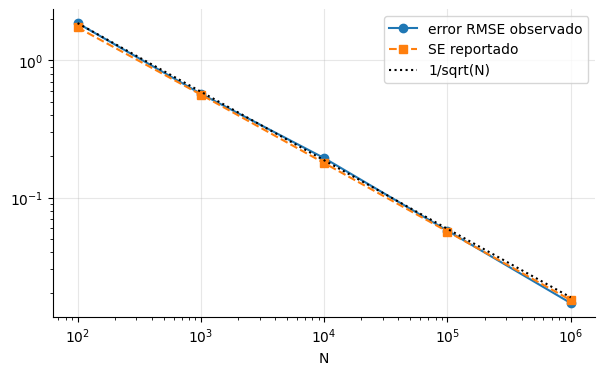

Lectura:
  El error baja con pendiente -0.51: para ganar un decimal (error /10) hay que simular 100 veces mas trayectorias.
  El intervalo de confianza del 95% cubre el valor verdadero en 92% a 100% de las repeticiones (nominal 95%).


In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(conv.index, conv["error_RMSE"], "o-", label="error RMSE observado"); ax.loglog(conv.index, conv["SE_reportado"], "s--", label="SE reportado")
ax.loglog(conv.index, conv["error_RMSE"].iloc[0] * np.sqrt(conv.index[0] / conv.index), "k:", label="1/sqrt(N)"); ax.set_xlabel("N"); ax.legend(); plt.show()
print("Lectura:")
print(f"  El error baja con pendiente {pendiente:.2f}: para ganar un decimal (error /10) hay que simular 100 veces mas trayectorias.")
print(f"  El intervalo de confianza del 95% cubre el valor verdadero en {conv['cobertura_IC95'].min():.0%} a {conv['cobertura_IC95'].max():.0%} de las repeticiones (nominal 95%).")

## 4. Reducción de varianza

### 4.1 Variables antitéticas y de control

- **Antitéticas:** por cada $Z$ se usa también $-Z$. Como el pago es monótono en $Z$, los dos pagos están **negativamente correlacionados** y el promedio por par tiene menos varianza.
- **Variable de control:** se usa $Y=S_T$ (de media conocida $S_0e^{rT}$) para corregir: $\hat C_{cv}=\overline{X}-b(\overline Y-\mathbb E[Y])$ con $b=\operatorname{Cov}(X,Y)/\operatorname{Var}(Y)$.

In [5]:
def pagos(z): return np.exp(-r * T) * np.maximum(S0 * np.exp((r - 0.5 * sig ** 2) * T + sig * np.sqrt(T) * z) - K, 0)

def estimadores(N_, seed):
    rg = np.random.default_rng(seed); z = rg.standard_normal(N_)
    x = pagos(z); simple = x.mean()
    anti = 0.5 * (pagos(z) + pagos(-z)).mean()
    ST = S0 * np.exp((r - 0.5 * sig ** 2) * T + sig * np.sqrt(T) * z); y = np.exp(-r * T) * ST                  # control: valor descontado de S_T, media conocida S0
    b = np.cov(x, y)[0, 1] / np.var(y, ddof=1); cv = x.mean() - b * (y.mean() - S0)
    xa = 0.5 * (pagos(z) + pagos(-z)); ya = 0.5 * (np.exp(-r * T) * ST + np.exp(-r * T) * S0 * np.exp((r - 0.5 * sig ** 2) * T - sig * np.sqrt(T) * z))
    ba = np.cov(xa, ya)[0, 1] / np.var(ya, ddof=1); anti_cv = xa.mean() - ba * (ya.mean() - S0)
    return simple, anti, cv, anti_cv

N_ = 10_000; R = 400
est = np.array([estimadores(N_, s) for s in range(R)])
nombres = ["simple", "antiteticas", "control", "antiteticas + control"]
vr = pd.DataFrame({"sesgo": est.mean(0) - C_BS, "desvio": est.std(0)}, index=nombres)
vr["factor_reduccion_varianza"] = (vr.loc["simple", "desvio"] / vr["desvio"]) ** 2
vr.round(6)

,sesgo,desvio,factor_reduccion_varianza
simple,-0.0067,0.1858,1.0000
antiteticas,-0.0027,0.0988,3.5409
control,-0.0029,0.0721,6.6519
antiteticas + control,0.0015,0.0253,54.0586


In [6]:
print("Lectura (call en el dinero, N=10.000 por estimacion, 400 repeticiones):")
for m in nombres[1:]:
    print(f"  {m:24s}: varianza {vr.loc[m, 'factor_reduccion_varianza']:.1f}x menor que el MC simple (desvio {vr.loc[m, 'desvio']:.5f} vs {vr.loc['simple', 'desvio']:.5f}).")
print(f"  Todos son insesgados: sesgo maximo = {vr['sesgo'].abs().max():.2e} (menor que su propio desvio / sqrt(R) = {vr['desvio'].max() / np.sqrt(R):.2e}).")
print("  Una reduccion de varianza de 4x equivale a simular 4 veces mas trayectorias sin costo adicional.")

Lectura (call en el dinero, N=10.000 por estimacion, 400 repeticiones):
  antiteticas             : varianza 3.5x menor que el MC simple (desvio 0.09875 vs 0.18583).
  control                 : varianza 6.7x menor que el MC simple (desvio 0.07205 vs 0.18583).
  antiteticas + control   : varianza 54.1x menor que el MC simple (desvio 0.02527 vs 0.18583).
  Todos son insesgados: sesgo maximo = 6.68e-03 (menor que su propio desvio / sqrt(R) = 9.29e-03).
  Una reduccion de varianza de 4x equivale a simular 4 veces mas trayectorias sin costo adicional.


### 4.2 Muestreo por importancia: una opción muy fuera del dinero

Con $K=250$ (2,5× el precio inicial) casi ninguna trayectoria termina sobre el strike: el MC simple tiene pagos nulos casi siempre y una **varianza relativa enorme**. Se **desplaza la media** de $Z$ hacia la región relevante (de modo que $S_T$ tenga mediana en $K$) y se corrige con la razón de verosimilitud $e^{-\theta Z+\theta^2/2}$.

In [7]:
K2 = 250.0; C2 = bs(S0, K2, T, r, sig)
theta = (np.log(K2 / S0) - (r - 0.5 * sig ** 2) * T) / (sig * np.sqrt(T))
def mc_importancia(N_, seed, th):
    rg = np.random.default_rng(seed); z = rg.standard_normal(N_) + th                                   # Z ~ N(th, 1)
    ST = S0 * np.exp((r - 0.5 * sig ** 2) * T + sig * np.sqrt(T) * z); w = np.exp(-th * z + 0.5 * th ** 2)
    return (np.exp(-r * T) * np.maximum(ST - K2, 0) * w).mean()
Nn = 20_000
est_s = np.array([np.exp(-r * T) * np.maximum(S0 * np.exp((r - 0.5 * sig ** 2) * T + sig * np.sqrt(T) * np.random.default_rng(s).standard_normal(Nn)) - K2, 0).mean() for s in range(300)])
est_i = np.array([mc_importancia(Nn, s, theta) for s in range(300)])
print(f"Precio exacto de la call con K=250: {C2:.6f}")
print(f"MC simple:      media {est_s.mean():.6f} | desvio relativo {est_s.std() / C2:.1%} | repeticiones con estimacion EXACTAMENTE 0: {(est_s == 0).mean():.0%}")
print(f"Importancia:    media {est_i.mean():.6f} | desvio relativo {est_i.std() / C2:.1%}")
print(f"Factor de reduccion de varianza: {(est_s.std() / est_i.std()) ** 2:.0f}x")

Precio exacto de la call con K=250: 0.001888
MC simple:      media 0.001822 | desvio relativo 88.6% | repeticiones con estimacion EXACTAMENTE 0: 10%
Importancia:    media 0.001888 | desvio relativo 1.0%
Factor de reduccion de varianza: 8291x


## 5. Griegos

Se estima $\Delta=\partial C/\partial S_0$ y $\mathcal V=\partial C/\partial\sigma$ de tres maneras:

1. **Pathwise:** derivar el pago dentro del valor esperado. Para la call: $\Delta=e^{-rT}\mathbf 1\{S_T>K\}\,S_T/S_0$.
2. **Razón de verosimilitud (LR):** derivar la densidad. $\Delta=e^{-rT}\,\text{pago}\cdot\dfrac{Z}{S_0\sigma\sqrt T}$.
3. **Diferencias finitas** (bump and revalue): $[C(S_0+h)-C(S_0-h)]/2h$, con **números aleatorios independientes** o **comunes** (los mismos $Z$ en ambos precios).

In [8]:
def delta_estimadores(N_, seed, h=1.0):
    rg = np.random.default_rng(seed); z = rg.standard_normal(N_); z2 = rg.standard_normal(N_)
    f = lambda s0, zz: np.exp(-r * T) * np.maximum(s0 * np.exp((r - 0.5 * sig ** 2) * T + sig * np.sqrt(T) * zz) - K, 0)
    ST = S0 * np.exp((r - 0.5 * sig ** 2) * T + sig * np.sqrt(T) * z)
    pathwise = (np.exp(-r * T) * (ST > K) * ST / S0).mean()
    lr = (f(S0, z) * z / (S0 * sig * np.sqrt(T))).mean()
    fd_indep = (f(S0 + h, z).mean() - f(S0 - h, z2).mean()) / (2 * h)
    fd_crn = (f(S0 + h, z).mean() - f(S0 - h, z).mean()) / (2 * h)
    return pathwise, lr, fd_indep, fd_crn

D_BS = delta_bs(S0, K, T, r, sig)
R = 300; Nd = 10_000
ed = np.array([delta_estimadores(Nd, s) for s in range(R)])
nom = ["pathwise", "razon de verosimilitud", "dif. finitas independientes", "dif. finitas comunes (CRN)"]
gr = pd.DataFrame({"media": ed.mean(0), "sesgo": ed.mean(0) - D_BS, "desvio": ed.std(0)}, index=nom)
print(f"Delta de Black-Scholes: {D_BS:.5f}")
gr.round(5)

Delta de Black-Scholes: 0.59677


,media,sesgo,desvio
pathwise,0.5968,-0.0000,0.0064
razon de verosimilitud,0.5958,-0.0010,0.0153
dif. finitas independientes,0.5992,0.0024,0.1283
dif. finitas comunes (CRN),0.5967,-0.0001,0.0064


In [9]:
print("Lectura (delta de una call en el dinero; N=10.000, 300 repeticiones):")
base = gr.loc["pathwise", "desvio"]
for m in nom: print(f"  {m:30s}: desvio {gr.loc[m, 'desvio']:.5f} ({gr.loc[m, 'desvio'] / base:.1f}x el de pathwise), sesgo {gr.loc[m, 'sesgo']:+.5f}")
print(f"  Las diferencias finitas con numeros INDEPENDIENTES tienen un desvio {gr.loc['dif. finitas independientes', 'desvio'] / gr.loc['dif. finitas comunes (CRN)', 'desvio']:.0f} veces mayor que con numeros COMUNES: al restar dos estimaciones ruidosas e independientes, el ruido se suma y el h pequeno lo amplifica.")

Lectura (delta de una call en el dinero; N=10.000, 300 repeticiones):
  pathwise                      : desvio 0.00644 (1.0x el de pathwise), sesgo -0.00002
  razon de verosimilitud        : desvio 0.01534 (2.4x el de pathwise), sesgo -0.00101
  dif. finitas independientes   : desvio 0.12830 (19.9x el de pathwise), sesgo +0.00239
  dif. finitas comunes (CRN)    : desvio 0.00637 (1.0x el de pathwise), sesgo -0.00010
  Las diferencias finitas con numeros INDEPENDIENTES tienen un desvio 20 veces mayor que con numeros COMUNES: al restar dos estimaciones ruidosas e independientes, el ruido se suma y el h pequeno lo amplifica.


### 5.1 Cuando pathwise falla: la opción digital

Una opción **digital** paga 1 si $S_T>K$. Su pago es **discontinuo** en $S_T$: derivarlo dentro del valor esperado da cero casi seguramente (el pago es localmente constante), así que el estimador pathwise **vale 0** y no converge al delta verdadero. Los estimadores LR y de diferencias finitas sí funcionan.

In [10]:
def delta_digital(N_, seed, h=1.0):
    rg = np.random.default_rng(seed); z = rg.standard_normal(N_)
    f = lambda s0, zz: np.exp(-r * T) * (s0 * np.exp((r - 0.5 * sig ** 2) * T + sig * np.sqrt(T) * zz) > K)
    pathwise = 0.0                                                                     # d(1{S_T>K})/dS0 = 0 casi seguramente
    lr = (f(S0, z) * z / (S0 * sig * np.sqrt(T))).mean()
    fd = (f(S0 + h, z).mean() - f(S0 - h, z).mean()) / (2 * h)
    return pathwise, lr, fd

d1_ = (np.log(S0 / K) + (r + 0.5 * sig ** 2) * T) / (sig * np.sqrt(T)); d2_ = d1_ - sig * np.sqrt(T)
D_DIG = np.exp(-r * T) * N.pdf(d2_) / (S0 * sig * np.sqrt(T))                          # delta cerrado de la digital
ed2 = np.array([delta_digital(50_000, s, h=2.0) for s in range(200)])
dg = pd.DataFrame({"media": ed2.mean(0), "desvio": ed2.std(0)}, index=["pathwise (naive)", "razon de verosimilitud", "dif. finitas CRN"])
print(f"Delta verdadero de la digital: {D_DIG:.5f}")
dg.round(5)

Delta verdadero de la digital: 0.01549


,media,desvio
pathwise (naive),0.0000,0.0000
razon de verosimilitud,0.0155,0.0001
dif. finitas CRN,0.0155,0.0003


In [11]:
print("Lectura:")
print(f"  El estimador pathwise da {dg.loc['pathwise (naive)', 'media']:.3f} (siempre cero), frente al delta verdadero de {D_DIG:.4f}: sesgo del {abs(dg.loc['pathwise (naive)', 'media'] / D_DIG - 1):.0%}. No es un problema de varianza: es un estimador INCORRECTO para pagos discontinuos.")
print(f"  LR: {dg.loc['razon de verosimilitud', 'media']:.5f} y diferencias finitas CRN: {dg.loc['dif. finitas CRN', 'media']:.5f}: ambos se acercan al valor verdadero.")

Lectura:
  El estimador pathwise da 0.000 (siempre cero), frente al delta verdadero de 0.0155: sesgo del 100%. No es un problema de varianza: es un estimador INCORRECTO para pagos discontinuos.
  LR: 0.01548 y diferencias finitas CRN: 0.01547: ambos se acercan al valor verdadero.


## 6. Opciones dependientes de la trayectoria

### 6.1 Asiática aritmética con control geométrico

El promedio **aritmético** de los precios no tiene fórmula cerrada, pero el **geométrico** sí (su logaritmo es normal), y ambos están muy correlacionados. Se usa la asiática geométrica como **variable de control**.

In [12]:
def trayectorias(N_, M, seed, T_=T):
    rg = np.random.default_rng(seed); dt = T_ / M
    z = rg.standard_normal((N_, M)); inc = (r - 0.5 * sig ** 2) * dt + sig * np.sqrt(dt) * z
    return S0 * np.exp(np.cumsum(inc, axis=1))

def geometrica_cerrada(M, K_=K):
    dt = T / M; i = np.arange(1, M + 1)
    mu_g = np.log(S0) + (r - 0.5 * sig ** 2) * dt * (M + 1) / 2
    cov = np.minimum.outer(i, i) * dt; var_g = sig ** 2 * cov.sum() / M ** 2
    sg = np.sqrt(var_g); d1 = (mu_g + var_g - np.log(K_)) / sg; d2 = d1 - sg
    return np.exp(-r * T) * (np.exp(mu_g + 0.5 * var_g) * N.cdf(d1) - K_ * N.cdf(d2))

M = 12; G_EXACTO = geometrica_cerrada(M)
def asiaticas(N_, seed):
    S = trayectorias(N_, M, seed); aritm = np.exp(-r * T) * np.maximum(S.mean(1) - K, 0); geo = np.exp(-r * T) * np.maximum(np.exp(np.log(S).mean(1)) - K, 0)
    b = np.cov(aritm, geo)[0, 1] / np.var(geo, ddof=1)
    return aritm.mean(), aritm.mean() - b * (geo.mean() - G_EXACTO), geo.mean()
ea = np.array([asiaticas(20_000, s) for s in range(100)])
print(f"Geometrica cerrada (M={M}): {G_EXACTO:.5f} | MC de la geometrica: {ea[:, 2].mean():.5f} (verificacion)")
print(f"Aritmetica: MC simple {ea[:, 0].mean():.5f} (desvio {ea[:, 0].std():.5f}) | con control geometrico {ea[:, 1].mean():.5f} (desvio {ea[:, 1].std():.5f})")
print(f"Factor de reduccion de varianza: {(ea[:, 0].std() / ea[:, 1].std()) ** 2:.0f}x")

Geometrica cerrada (M=12): 6.51942 | MC de la geometrica: 6.51863 (verificacion)
Aritmetica: MC simple 6.81706 (desvio 0.06966) | con control geometrico 6.81788 (desvio 0.00223)
Factor de reduccion de varianza: 977x


### 6.2 Barrera con monitoreo discreto: el sesgo de discretización

Una call **down-and-out** (se anula si el subyacente toca la barrera $H$) con monitoreo **continuo** tiene fórmula cerrada. Pero un MC solo observa la barrera en $M$ fechas, de modo que **se pierden cruces entre fechas** y el precio simulado es **mayor** (la opción sobrevive más). Broadie, Glasserman y Kou muestran que el precio con monitoreo discreto se aproxima por el continuo con la barrera **desplazada** $H'=H\,e^{-\beta\sigma\sqrt{\Delta t}}$, $\beta\approx0{,}5826$.

In [13]:
H = 85.0
def down_out_continuo(H_, K_=K):
    lam = (r + 0.5 * sig ** 2) / sig ** 2; y = np.log(H_ ** 2 / (S0 * K_)) / (sig * np.sqrt(T)) + lam * sig * np.sqrt(T)
    c_di = S0 * (H_ / S0) ** (2 * lam) * N.cdf(y) - K_ * np.exp(-r * T) * (H_ / S0) ** (2 * lam - 2) * N.cdf(y - sig * np.sqrt(T))
    return bs(S0, K_, T, r, sig) - c_di

def mc_barrera(N_, M_, seed):
    pagos_ = []; rg_seed = seed
    for ch in range(N_ // 20_000):
        S = trayectorias(20_000, M_, rg_seed + ch); vivo = S.min(axis=1) > H; pagos_.append(np.exp(-r * T) * np.maximum(S[:, -1] - K, 0) * vivo)
    p = np.concatenate(pagos_); return p.mean(), p.std(ddof=1) / np.sqrt(len(p))

C_CONT = down_out_continuo(H)
filas = []
for M_ in (4, 12, 52, 252):
    pr, se = mc_barrera(400_000, M_, 7000 + M_); H_bgk = H * np.exp(-0.5826 * sig * np.sqrt(T / M_)); aprox = down_out_continuo(H_bgk)
    filas.append({"M_fechas": M_, "MC_discreto": pr, "SE": se, "continuo_cerrado": C_CONT, "sesgo_continuo_vs_MC": C_CONT - pr, "BGK_aprox": aprox, "error_BGK": aprox - pr})
bar = pd.DataFrame(filas).set_index("M_fechas")
bar.round(4)

,MC_discreto,SE,continuo_cerrado,sesgo_continuo_vs_MC,BGK_aprox,error_BGK
M_fechas,,,,,,
4,11.0746,0.0284,10.1239,-0.9508,11.0424,-0.0322
12,10.8048,0.0284,10.1239,-0.6809,10.7806,-0.0242
52,10.4714,0.0282,10.1239,-0.3476,10.4928,0.0213
252,10.2939,0.0282,10.1239,-0.1701,10.3053,0.0114


In [14]:
print("Lectura (down-and-out, H=85):")
print(f"  Con M=4 fechas, el MC discreto da {bar.loc[4, 'MC_discreto']:.3f} frente al continuo {C_CONT:.3f}: la opcion simulada vale {(bar.loc[4, 'MC_discreto'] / C_CONT - 1) * 100:.0f}% MAS, porque se pierden cruces entre fechas.")
print(f"  El sesgo cae al subir M: |continuo - MC| = {', '.join(f'M={m}: {abs(bar.loc[m, 'sesgo_continuo_vs_MC']):.3f}' for m in bar.index)} (decae ~ 1/sqrt(M)).")
print(f"  La correccion BGK reduce el error de {abs(bar.loc[4, 'sesgo_continuo_vs_MC']):.3f} a {abs(bar.loc[4, 'error_BGK']):.3f} con M=4 y de {abs(bar.loc[52, 'sesgo_continuo_vs_MC']):.3f} a {abs(bar.loc[52, 'error_BGK']):.3f} con M=52.")

Lectura (down-and-out, H=85):
  Con M=4 fechas, el MC discreto da 11.075 frente al continuo 10.124: la opcion simulada vale 9% MAS, porque se pierden cruces entre fechas.
  El sesgo cae al subir M: |continuo - MC| = M=4: 0.951, M=12: 0.681, M=52: 0.348, M=252: 0.170 (decae ~ 1/sqrt(M)).
  La correccion BGK reduce el error de 0.951 a 0.032 con M=4 y de 0.348 a 0.021 con M=52.


## 7. Pruebas automáticas

In [15]:
# 7.1 la formula cerrada: paridad put-call e integracion numerica
assert abs((C_BS - P_BS) - (S0 - K * np.exp(-r * T))) < 1e-12 and abs(integral - C_BS) < 1e-9
assert abs(integral_sin_partir - C_BS) > 1e-6, 'integrar sin partir en el quiebre debe perder precision'
# 7.2 convergencia: pendiente ~ -0.5 y cobertura de los IC cercana al 95%
assert -0.6 < pendiente < -0.4 and conv["cobertura_IC95"].between(0.88, 1.0).all()
# 7.3 todos los estimadores son insesgados dentro del error de Monte Carlo y las tecnicas reducen la varianza
assert (vr["sesgo"].abs() < 4 * vr["desvio"] / np.sqrt(400)).all()
assert vr.loc["antiteticas", "factor_reduccion_varianza"] > 1.5 and vr.loc["control", "factor_reduccion_varianza"] > 1.5
assert vr.loc["antiteticas + control", "factor_reduccion_varianza"] >= max(vr.loc["antiteticas", "factor_reduccion_varianza"], vr.loc["control", "factor_reduccion_varianza"]) * 0.8
# 7.4 importancia: para una opcion muy fuera del dinero, reduccion enorme de varianza y el MC simple da cero a menudo
assert (est_s.std() / est_i.std()) ** 2 > 20 and abs(est_i.mean() / C2 - 1) < 0.05
# 7.5 griegos: los estimadores son insesgados; diferencias finitas independientes son mucho mas ruidosas que con numeros comunes
assert (gr["sesgo"].abs() < 4 * gr["desvio"] / np.sqrt(R) + 2e-3).all()
assert gr.loc["dif. finitas independientes", "desvio"] > 5 * gr.loc["dif. finitas comunes (CRN)", "desvio"]
assert gr.loc["pathwise", "desvio"] < gr.loc["razon de verosimilitud", "desvio"]
# 7.6 la digital: pathwise vale cero (incorrecto); LR y FD-CRN estiman el delta verdadero
assert dg.loc["pathwise (naive)", "media"] == 0 and D_DIG > 0
assert abs(dg.loc["razon de verosimilitud", "media"] / D_DIG - 1) < 0.1 and abs(dg.loc["dif. finitas CRN", "media"] / D_DIG - 1) < 0.1
# 7.7 asiatica: la geometrica simulada coincide con la cerrada y el control geometrico reduce mucho la varianza
assert abs(ea[:, 2].mean() / G_EXACTO - 1) < 0.01 and (ea[:, 0].std() / ea[:, 1].std()) ** 2 > 20
# 7.8 barrera: el MC discreto sobrevalua frente al continuo; el sesgo cae con M; BGK reduce el error
assert (bar["sesgo_continuo_vs_MC"] < 0).all() and bar["sesgo_continuo_vs_MC"].abs().is_monotonic_decreasing
assert (bar["error_BGK"].abs() < bar["sesgo_continuo_vs_MC"].abs()).all()
assert abs(bar.loc[252, "MC_discreto"] - C_CONT) < 0.1 * C_CONT
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| MC simple | El error baja como 1/√N y el IC95 % cubre aproximadamente lo nominal | Reportar siempre el error estándar |
| Reducción de varianza | Antitéticas y control reducen la varianza varias veces sin sesgo; el muestreo por importancia la reduce enormemente para opciones muy fuera del dinero | Usar el conocimiento del problema para reducir varianza antes de simular más |
| Griegos | Pathwise es el más preciso en pagos continuos; las diferencias finitas con números independientes son mucho más ruidosas que con números comunes | Usar números aleatorios comunes en las diferencias finitas |
| Opción digital | El estimador pathwise da cero: es incorrecto para pagos discontinuos | Verificar el estimador contra un caso con solución cerrada |
| Asiática | El control geométrico reduce la varianza de la aritmética en más de un orden de magnitud | Elegir controles muy correlacionados con media conocida |
| Barrera discreta | Discretizar sobrevalúa (se pierden cruces); el sesgo cae como 1/√M y la corrección BGK lo reduce mucho | Corregir el desplazamiento de la barrera o aumentar el monitoreo |

**Límites que no deben ocultarse**

- El subyacente sigue un movimiento browniano geométrico con volatilidad constante; con saltos o volatilidad estocástica no hay soluciones cerradas para verificar.
- Los factores de reducción de varianza dependen de la opción y los parámetros (aquí: call en el dinero, T=1, σ=25 %).
- No se trata la valoración de opciones americanas, que exige regresión (Longstaff-Schwartz) o árboles.
- La corrección BGK es una aproximación asintótica y es más precisa con monitoreo más frecuente.
- Datos sintéticos: ningún valor numérico es extrapolable a un instrumento real.